# Comprensión y preparación de los datos (CRISP-DM)

Notebook del componente Python de CashPyme. Cubre las fases 2 y 3 de **CRISP-DM** sobre el
dataset de flujo de caja diario que usará el modelo de proyección:

1. **Comprensión del negocio**: qué tiene que responder el modelo (resumen).
2. **Comprensión de los datos**: origen, estructura, estadísticas, tendencia y estacionalidad.
3. **Preparación de los datos**: huecos, duplicados, anulados, outliers y dataset final.

El dataset es **sintético** (ver `DATASET.md`): no hay datos históricos reales de una pyme. Todo
lo que se concluye acá describe la pyme simulada, no a una pyme real.

Para volver a ejecutarlo: `cd analitica`, `.venv\Scripts\pip install -r requirements-notebook.txt`
y abrir este archivo en VS Code o con `.venv\Scripts\jupyter lab`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from cashpyme_dataset.validacion import validar

CSV = RAIZ / "datos" / "flujo_diario_sintetico.csv"
meta = json.loads(CSV.with_suffix(".meta.json").read_text(encoding="utf-8"))
df = pd.read_csv(CSV, parse_dates=["fecha"], keep_default_na=False)

pd.set_option("display.float_format", lambda v: f"{v:,.0f}".replace(",", "."))
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
ORDEN_DIAS = ["lunes", "martes", "miercoles", "jueves", "viernes", "sabado", "domingo"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
pesos = lambda v: f"${v:,.0f}".replace(",", ".")

## 1. Comprensión del negocio

CashPyme quiere **anticipar** la caja de una pyme, no solo registrarla: proyectar el saldo a 30,
60 y 90 días para avisar antes de quedarse sin caja. El modelo aprende de la serie diaria de
ingresos y egresos registrados (`movimiento_financiero`, agregada como `vista_flujo_diario`).

Para eso los datos tienen que: (a) tener un origen conocido y reproducible, (b) cubrir cada día
sin huecos sin explicar, y (c) no tener duplicados ni valores anómalos sin revisar.

## 2. Comprensión de los datos

### 2.1 Origen y trazabilidad

In [2]:
print("Origen:     ", meta["origen"])
print("Generador:  ", meta["generador"])
print("Semilla:    ", meta["semilla"])
print("Rango:      ", meta["fecha_inicio"], "a", meta["fecha_fin"], f"({meta['filas']} días)")
print("Reproducir: ", meta["como_reproducir"])
problemas = validar(CSV)
print("\nValidación: ", "sin problemas (sha256, rango, huecos, motivos, montos)" if not problemas else problemas)

Origen:      sintetico
Generador:   analitica/cashpyme_dataset/sintetico.py
Semilla:     42
Rango:       2024-01-01 a 2025-12-31 (731 días)
Reproducir:  cd analitica && python generar_sintetico.py --semilla 42 --desde 2024-01-01 --hasta 2025-12-31

Validación:  sin problemas (sha256, rango, huecos, motivos, montos)


El archivo coincide con su ficha (el sha256 cuadra) y se puede regenerar idéntico con la semilla.
La ficha completa, con todos los supuestos de la simulación, está en `DATASET.md`.

### 2.2 Estructura

In [3]:
print(df.shape[0], "filas x", df.shape[1], "columnas\n")
print(df.dtypes.to_string())
df.head(8)

731 filas x 12 columnas

fecha                     datetime64[us]
dia_semana                           str
ingresos                           int64
egresos                            int64
flujo_neto                         int64
flujo_acumulado                    int64
cantidad_ingresos                  int64
cantidad_egresos                   int64
dia_sin_movimientos                int64
motivo_sin_movimientos               str
outlier_ingresos                   int64
outlier_egresos                    int64


,fecha,dia_semana,ingresos,egresos,flujo_neto,flujo_acumulado,cantidad_ingresos,cantidad_egresos,dia_sin_movimientos,motivo_sin_movimientos,outlier_ingresos,outlier_egresos
0,2024-01-01,lunes,0,0,0,0,0,0,1,feriado,0,0
1,2024-01-02,martes,452163,117955,334208,334208,3,2,0,,0,1
2,2024-01-03,miercoles,332469,34439,298030,632238,3,1,0,,0,0
3,2024-01-04,jueves,1606213,564801,1041412,1673650,4,3,0,,0,0
4,2024-01-05,viernes,524815,1141178,-616363,1057287,3,2,0,,0,0
5,2024-01-06,sabado,426100,29493,396607,1453894,3,2,0,,0,0
6,2024-01-07,domingo,0,0,0,1453894,0,0,1,domingo,0,0
7,2024-01-08,lunes,358522,57496,301026,1754920,3,2,0,,0,0


### 2.3 Estadísticas descriptivas (días con movimientos)

In [4]:
abiertos = df[df["dia_sin_movimientos"] == 0]
abiertos[["ingresos", "egresos", "flujo_neto", "cantidad_ingresos", "cantidad_egresos"]].describe()

,ingresos,egresos,flujo_neto,cantidad_ingresos,cantidad_egresos
count,597,597,597,597,597
mean,585.384,552.847,32.536,3,2
std,298.086,764.600,820.818,0,1
min,186.371,0,-3.892.641,3,0
25%,402.865,31.049,-340.415,3,1
50%,500.797,115.585,299.254,3,2
75%,645.764,862.341,496.479,3,2
max,1.949.970,4.248.455,1.949.970,4,4


In [5]:
print(f"Días con flujo neto negativo: {(df['flujo_neto'] < 0).sum()} de {len(df)}")
print(f"Flujo acumulado mínimo: {pesos(df['flujo_acumulado'].min())} el {df.loc[df['flujo_acumulado'].idxmin(), 'fecha']:%d-%m-%Y}")
print(f"Flujo acumulado final:  {pesos(df['flujo_acumulado'].iloc[-1])}")

Días con flujo neto negativo: 236 de 731
Flujo acumulado mínimo: $-644.717 el 28-03-2024
Flujo acumulado final:  $19.424.001


### 2.4 La serie en el tiempo

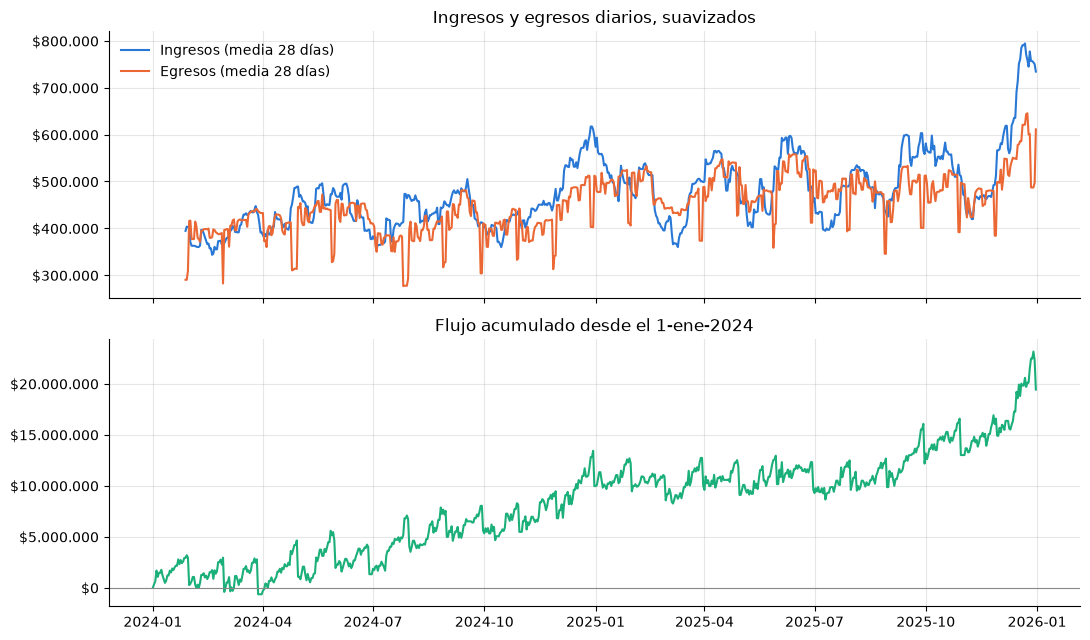

In [6]:
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
serie = df.set_index("fecha")
a.plot(serie["ingresos"].rolling(28).mean(), label="Ingresos (media 28 días)", color="#2a78d6")
a.plot(serie["egresos"].rolling(28).mean(), label="Egresos (media 28 días)", color="#eb6834")
a.set_title("Ingresos y egresos diarios, suavizados")
a.yaxis.set_major_formatter(lambda v, _: pesos(v))
a.legend(frameon=False)
b.plot(serie["flujo_acumulado"], color="#1baf7a")
b.axhline(0, color="#888", lw=0.8)
b.set_title("Flujo acumulado desde el 1-ene-2024")
b.yaxis.set_major_formatter(lambda v, _: pesos(v))
plt.tight_layout()

### 2.5 Estacionalidad semanal y mensual

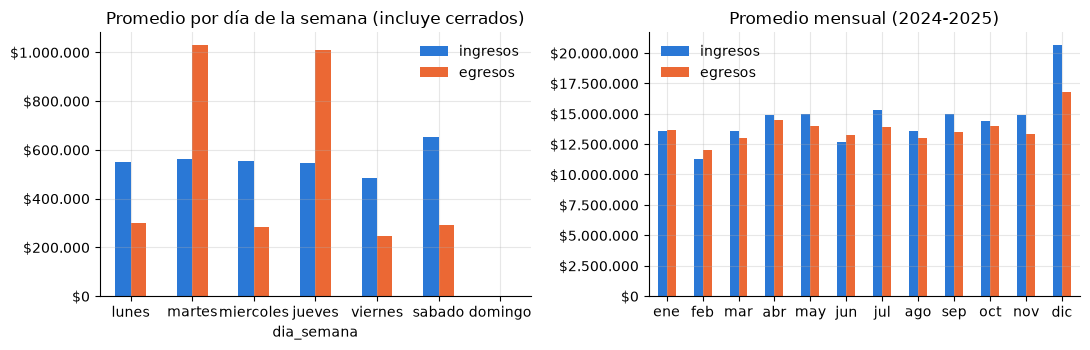

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
por_dia = df.groupby("dia_semana")[["ingresos", "egresos"]].mean().reindex(ORDEN_DIAS)
por_dia.plot.bar(ax=a, color=["#2a78d6", "#eb6834"], rot=0)
a.set_title("Promedio por día de la semana (incluye cerrados)")
a.yaxis.set_major_formatter(lambda v, _: pesos(v))
a.legend(frameon=False)

por_mes = df.groupby(df["fecha"].dt.month)[["ingresos", "egresos"]].sum() / df["fecha"].dt.year.nunique()
por_mes.index = MESES
por_mes.plot.bar(ax=b, color=["#2a78d6", "#eb6834"], rot=0)
b.set_title("Promedio mensual (2024-2025)")
b.yaxis.set_major_formatter(lambda v, _: pesos(v))
b.legend(frameon=False)
plt.tight_layout()

### 2.6 Días sin movimientos y distribución de los montos

motivo_sin_movimientos
domingo    98
feriado    36


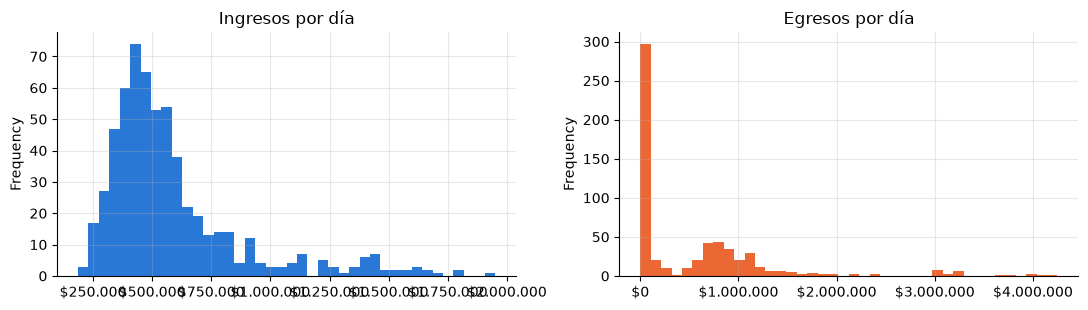

In [8]:
print(df[df["dia_sin_movimientos"] == 1]["motivo_sin_movimientos"].value_counts().to_string())
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
abiertos["ingresos"].plot.hist(bins=40, ax=a, color="#2a78d6")
a.set_title("Ingresos por día")
a.xaxis.set_major_formatter(lambda v, _: pesos(v))
abiertos["egresos"].plot.hist(bins=40, ax=b, color="#eb6834")
b.set_title("Egresos por día")
b.xaxis.set_major_formatter(lambda v, _: pesos(v))
plt.tight_layout()

**Lo que muestran los datos**

- **Tendencia**: los ingresos crecen de forma leve y sostenida; el flujo acumulado sube con
  caídas puntuales en los meses flojos.
- **Estacionalidad semanal**: el sábado vende más que el resto y el domingo es siempre cero
  (la pyme no abre). Martes y jueves tienen los egresos más altos: son los días de pago a
  proveedores.
- **Estacionalidad anual**: diciembre es el mejor mes y febrero el más bajo.
- **Egresos a saltos**: la mayoría de los días se paga poco y unos pocos días concentran los
  pagos grandes (sueldos a fin de mes, arriendo, IVA). Por eso la distribución de egresos tiene
  una cola larga a la derecha.
- **Días en cero**: todos son domingos o feriados; no hay días hábiles sin movimientos.

Para el modelo esto significa que necesita variables de calendario (día de la semana, mes,
fin de mes, feriado): gran parte de la variación se explica por el calendario y no es ruido.

## 3. Preparación de los datos

### 3.1 Huecos de fechas

In [9]:
calendario = pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="D")
faltan = calendario.difference(df["fecha"])
print(f"Días del calendario: {len(calendario)}  |  filas: {len(df)}  |  días faltantes: {len(faltan)}")
vacios = df[df["dia_sin_movimientos"] == 1]
sin_motivo = vacios[vacios["motivo_sin_movimientos"] == ""]
print(f"Días sin movimientos: {len(vacios)}  |  sin motivo: {len(sin_motivo)}")

Días del calendario: 731  |  filas: 731  |  días faltantes: 0
Días sin movimientos: 134  |  sin motivo: 0


No falta ningún día y cada día sin movimientos dice por qué. Para el modelo son **ceros reales**
(la pyme estaba cerrada), no datos faltantes: no se imputan.

### 3.2 Duplicados y anulados

In [10]:
print("Fechas repetidas en el dataset:", int(df["fecha"].duplicated().sum()))
dup = meta["limpieza"]["duplicados"]
print("Movimientos duplicados:", dup["encontrados"], "-", dup["decision"])
print("Movimientos anulados excluidos:", meta["movimientos_generados"]["anulado"],
      "de", sum(meta["movimientos_generados"].values()))

Fechas repetidas en el dataset: 0
Movimientos duplicados: 0 - Se reportan y no se eliminan: dos movimientos iguales pueden ser legítimos.
Movimientos anulados excluidos: 27 de 2884


Cada fecha aparece una vez. Los movimientos anulados (duplicados corregidos en la app) quedan
fuera, igual que en `vista_flujo_diario`. Con datos reales, la regla de duplicados reporta
movimientos idénticos para revisarlos a mano en vez de borrarlos.

### 3.3 Outliers

In [11]:
print(meta["limpieza"]["outliers"]["regla"], "\n")
outliers = df[(df["outlier_ingresos"] == 1) | (df["outlier_egresos"] == 1)]
outliers[["fecha", "dia_semana", "ingresos", "egresos", "outlier_ingresos", "outlier_egresos"]]

Tukey sobre log(monto), por día de la semana: fuera de [Q1 - 3.0·IQR, Q3 + 3.0·IQR] entre los días con monto > 0 (mínimo 8 días por grupo). Un monto 0 (día sin egresos, por ejemplo) nunca es outlier. 



,fecha,dia_semana,ingresos,egresos,outlier_ingresos,outlier_egresos
1,2024-01-02,martes,452163,117955,0,1
120,2024-04-30,martes,444897,3993930,0,1
193,2024-07-12,viernes,1695018,194054,1,0
365,2024-12-31,martes,542737,4005036,0,1
638,2025-09-30,martes,355814,4248455,0,1


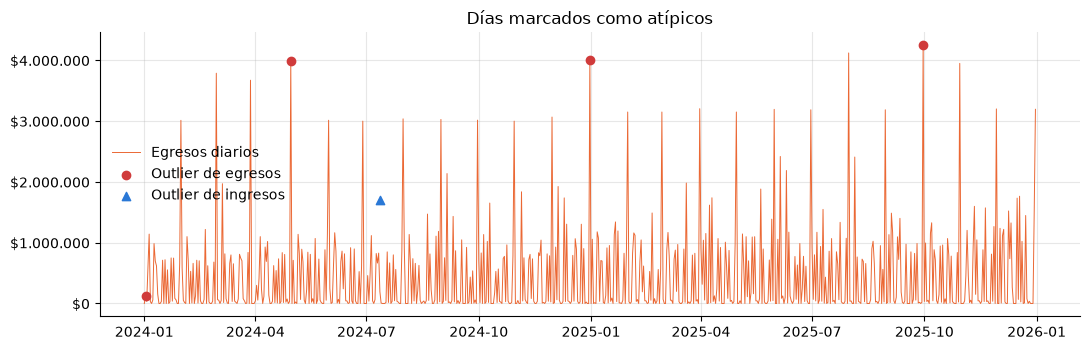

In [12]:
fig, ax = plt.subplots()
ax.plot(df["fecha"], df["egresos"], color="#eb6834", lw=0.7, label="Egresos diarios")
marcados = df[df["outlier_egresos"] == 1]
ax.scatter(marcados["fecha"], marcados["egresos"], color="#d03b3b", zorder=3, label="Outlier de egresos")
marcados = df[df["outlier_ingresos"] == 1]
ax.scatter(marcados["fecha"], marcados["ingresos"], color="#2a78d6", marker="^", zorder=3, label="Outlier de ingresos")
ax.yaxis.set_major_formatter(lambda v, _: pesos(v))
ax.set_title("Días marcados como atípicos")
ax.legend(frameon=False)
plt.tight_layout()

La regla se aplica sobre el **logaritmo** del monto y compara cada día con los del mismo día de
la semana. Así un día de sueldos no cuenta como anómalo (es normal en una pyme) y sí se detecta
algo desproporcionado, como un monto digitado con un cero de más (hay una prueba que lo
comprueba). Los pocos días marcados son explicables: martes de fin de mes en que coinciden
sueldos y proveedores, el primer día de la serie (sin historial de proveedores) y un cobro
grande a una empresa.

**Decisión**: los outliers **se marcan y no se eliminan**. Son días posibles para la pyme; el
modelo puede usarlos como variable o excluirlos del entrenamiento, y esa decisión se toma y se
documenta en la etapa de modelado.

### 3.4 Dataset listo para el modelo

In [13]:
modelo = df[["fecha", "ingresos", "egresos", "flujo_neto", "flujo_acumulado",
             "dia_sin_movimientos", "outlier_ingresos", "outlier_egresos"]].copy()
modelo["dia_semana"] = df["fecha"].dt.day_of_week        # 0 = lunes
modelo["mes"] = df["fecha"].dt.month
modelo["dia_del_mes"] = df["fecha"].dt.day
modelo["fin_de_mes"] = (df["fecha"] + pd.Timedelta(days=3)).dt.month.ne(df["fecha"].dt.month).astype(int)  # últimos 3 días
modelo["feriado"] = (df["motivo_sin_movimientos"] == "feriado").astype(int)

# Partición temporal (nunca al azar en series de tiempo): los últimos 92 días son la prueba.
corte = modelo["fecha"].max() - pd.Timedelta(days=91)
entrenamiento, prueba = modelo[modelo["fecha"] < corte], modelo[modelo["fecha"] >= corte]
print(f"Entrenamiento: {len(entrenamiento)} días ({entrenamiento['fecha'].min():%d-%m-%Y} a {entrenamiento['fecha'].max():%d-%m-%Y})")
print(f"Prueba:        {len(prueba)} días ({prueba['fecha'].min():%d-%m-%Y} a {prueba['fecha'].max():%d-%m-%Y})")
print("Valores nulos:", int(modelo.isna().sum().sum()))
modelo.tail()

Entrenamiento: 639 días (01-01-2024 a 30-09-2025)
Prueba:        92 días (01-10-2025 a 31-12-2025)
Valores nulos: 0


,fecha,ingresos,egresos,flujo_neto,flujo_acumulado,dia_sin_movimientos,outlier_ingresos,outlier_egresos,dia_semana,mes,dia_del_mes,fin_de_mes,feriado
726,2025-12-27,954400,0,954400,22452001,0,0,0,5,12,27,0,0
727,2025-12-28,0,0,0,22452001,1,0,0,6,12,28,0,0
728,2025-12-29,695864,0,695864,23147865,0,0,0,0,12,29,1,0
729,2025-12-30,682189,1521053,-838864,22309001,0,0,0,1,12,30,1,0
730,2025-12-31,309166,3194166,-2885000,19424001,0,0,0,2,12,31,1,0


## Resumen

| Revisión | Resultado |
|---|---|
| Origen | Sintético, documentado (semilla 42, supuestos en `DATASET.md`), reproducible byte a byte |
| Huecos de fechas | Ninguno: 731 días seguidos; los días en cero son domingos o feriados, con su motivo |
| Duplicados | Ninguna fecha repetida; sin movimientos duplicados; anulados excluidos |
| Outliers | Pocos días marcados, todos explicables; se marcan y no se eliminan |
| Nulos | Ninguno |

El dataset queda listo para la fase de **modelado**, con variables de calendario y una
partición temporal de entrenamiento y prueba. Al presentar resultados hay que recordar que miden
qué tan bien el modelo aprende la simulación, no una pyme real.